# Impacto das redes sociais no sucesso de filmes
Projeto de Análise de Dados (Sistemas Especialistas) — Amanda, Larissa e Raquel

**Pergunta principal:** O engajamento nas redes sociais pode indicar o sucesso de um filme?

**Como medimos:**
- *Engajamento nas redes:* curtidas no Facebook (filme, elenco e diretor) e sentimento dos comentários dos trailers no YouTube.
- *Sucesso:* bilheteria (`gross`) e nota no IMDb (`imdb_score`).



## Como reproduzir
1. Abra no Google Colab e entre com uma conta do Kaggle (`kagglehub.login()`, se o download pedir).
2. Se o Kaggle devolver erro 403, abra a página do dataset e aceite os termos de uso.
3. Execute **Ambiente > Executar tudo**. Os arquivos `filmes_limpo.csv`, `filmes_final.csv`, `filmes_final_reviews.csv` e `resultados_hipoteses.csv` são gerados na pasta do Colab.

## 0. Configuração e funções de apoio

In [ ]:
!pip install kagglehub scipy -q

import os
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from scipy import stats

sns.set_theme(style="whitegrid")

ALFA = 0.05        # nível de significância dos testes
MIN_MENCOES = 3    # mínimo de resenhas citando um filme para ele entrar na análise


def baixar_dataset(handle):
    """Baixa um dataset do Kaggle e devolve a pasta com os arquivos."""
    try:
        return kagglehub.dataset_download(handle)
    except Exception as erro:
        print(f"Não foi possível baixar '{handle}': {erro}")
        print("Dicas: rode kagglehub.login(), aceite os termos na página do dataset "
              f"(kaggle.com/datasets/{handle}) e confira se ele ainda existe.")
        raise


def descrever_base(df, nome):
    """Mostra o tamanho da base e devolve uma tabela com tipo e valores ausentes de cada coluna."""
    print(f"{nome}: {df.shape[0]} linhas x {df.shape[1]} colunas")
    return pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "preenchidos": df.notna().sum(),
        "ausentes (%)": (df.isna().mean() * 100).round(1),
    })


def classificar_forca(rho):
    """Classifica a força de uma correlação pelo valor absoluto."""
    a = abs(rho)
    if a < 0.10:
        return "desprezível"
    if a < 0.30:
        return "fraca"
    if a < 0.50:
        return "moderada"
    return "forte"


def correlacao_spearman(df, x, y):
    """Correlação de Spearman entre x e y, usando só as linhas que têm os dois valores.
    Usamos Spearman porque curtidas e bilheteria são muito assimétricas."""
    d = df[[x, y]].dropna()
    if len(d) < 10:
        return {"n": len(d), "rho": np.nan, "p": np.nan}
    rho, p = stats.spearmanr(d[x], d[y])
    return {"n": len(d), "rho": rho, "p": p}


def descrever_relacao(df, x, y, rotulo):
    """Imprime em uma frase o resultado da correlação entre x e y."""
    r = correlacao_spearman(df, x, y)
    if np.isnan(r["rho"]):
        print(f"{rotulo}: poucos dados (n = {r['n']}).")
        return r
    sentido = "positiva" if r["rho"] > 0 else "negativa"
    signif = "estatisticamente significativa" if r["p"] < ALFA else "não significativa"
    print(f"{rotulo}: Spearman = {r['rho']:.2f} (n = {r['n']}, p = {r['p']:.3g}) "
          f"-> relação {classificar_forca(r['rho'])} {sentido}, {signif}.")
    return r

## 1. Carregamento dos dados

In [ ]:
!pip install kagglehub -q
import kagglehub, os
import numpy as np
import pandas as pd

path = kagglehub.dataset_download("carolzhangdc/imdb-5000-movie-dataset")
df = pd.read_csv(os.path.join(path, "movie_metadata.csv"))
print(df.shape)

Using Colab cache for faster access to the 'imdb-5000-movie-dataset' dataset.
(5043, 28)


In [ ]:
# Dicionário rápido das 28 colunas originais: tipo e quanto falta em cada uma
descrever_base(df, "IMDB 5000 (original)")

**Colunas que mais usamos:** `movie_title`, `title_year`, `genres`, `country`, `imdb_score` (nota de 0 a 10), `gross` (bilheteria bruta em USD), `budget` (orçamento), `num_user_for_reviews` e `num_critic_for_reviews` (número de resenhas) e as curtidas no Facebook: `movie_facebook_likes` (página do filme), `director_facebook_likes`, `actor_1/2/3_facebook_likes` e `cast_total_facebook_likes`.

## 2. Limpeza dos dados


In [ ]:
def limpar_dados(df):
    """Limpa o dataset IMDB 5000 para a análise de redes sociais x sucesso."""
    df = df.copy()

    # Mantém só as colunas usadas nas hipóteses
    colunas = [
        "movie_title", "title_year", "genres", "country", "director_name",
        "director_facebook_likes", "actor_1_facebook_likes",
        "actor_2_facebook_likes", "actor_3_facebook_likes",
        "cast_total_facebook_likes", "movie_facebook_likes",
        "num_user_for_reviews", "num_critic_for_reviews",
        "imdb_score", "gross", "budget",
    ]
    df = df[colunas]

    # Duplicados
    df = df.drop_duplicates()

    # Padroniza texto (título vem com espaço invisível no fim)
    df["movie_title"] = df["movie_title"].str.replace("\xa0", "").str.strip()

    # Remove linhas sem as variáveis essenciais
    essenciais = ["gross", "imdb_score", "director_facebook_likes",
                  "actor_1_facebook_likes", "title_year",
                  "actor_2_facebook_likes", "actor_3_facebook_likes",
                  "num_user_for_reviews", "num_critic_for_reviews"]
    df = df.dropna(subset=essenciais)

    # Tipos
    df["title_year"] = df["title_year"].astype(int)

    # Zero em curtidas de diretor/filme = provável página inexistente
    for col in ["director_facebook_likes", "movie_facebook_likes"]:
        df[col] = df[col].replace(0, np.nan)

    # Orçamento fora dos EUA pode estar em moeda local
    df.loc[df["country"] != "USA", "budget"] = np.nan

    return df.reset_index(drop=True)


df_limpo = limpar_dados(df)
print("Antes:", df.shape, "| Depois:", df_limpo.shape)

Antes: (5043, 28) | Depois: (4059, 16)


## 3. Verificação

In [ ]:
print(df_limpo.isnull().sum())
print("\nDuplicados:", df_limpo.duplicated().sum())
print("\n", df_limpo[["gross", "budget", "imdb_score"]].describe())

# Conferência da decisão sobre o orçamento (usa o df original)
print("\nMaiores orçamentos do dataset original:")
print(df.nlargest(8, "budget")[["movie_title", "country", "budget"]])

movie_title                     0
title_year                      0
genres                          0
country                         0
director_name                   0
director_facebook_likes       696
actor_1_facebook_likes          0
actor_2_facebook_likes          0
actor_3_facebook_likes          0
cast_total_facebook_likes       0
movie_facebook_likes         1861
num_user_for_reviews            0
num_critic_for_reviews          0
imdb_score                      0
gross                           0
budget                       1057
dtype: int64

Duplicados: 0

               gross        budget   imdb_score
count  4.059000e+03  3.002000e+03  4059.000000
mean   4.794497e+07  3.967292e+07     6.465041
std    6.746281e+07  4.324176e+07     1.050890
min    1.620000e+02  2.180000e+02     1.600000
25%    5.255998e+06  1.000000e+07     5.900000
50%    2.529645e+07  2.500000e+07     6.600000
75%    6.144500e+07  5.400000e+07     7.200000
max    7.605058e+08  3.000000e+08     9.300000

Ma

In [ ]:
df_limpo.to_csv("filmes_limpo.csv", index=False)
print("Arquivo salvo:", df_limpo.shape)

Arquivo salvo: (4059, 16)


## Decisões de limpeza
- **Duplicados:** removemos 45 filmes repetidos, pois contariam o mesmo filme duas vezes.
- **Títulos:** removemos espaços invisíveis no final para padronizar o texto.
- **Bilheteria e curtidas ausentes:** removemos os filmes sem essas variáveis, essenciais às hipóteses. O dataset passou de 5.043 para 4.059 filmes.
- **Zeros em curtidas de diretor e de filme:** tratados como "sem dado", pois quase metade dos filmes com zero curtidas não é realista (provavelmente a página não existia).
- **Orçamento:** mantido só para filmes dos EUA. Os maiores valores eram de filmes da Coreia do Sul, Japão e Índia, provavelmente em moeda local. Restaram 3.002 filmes com orçamento.
- **Bilheteria alta (blockbusters):** mantida, pois são valores reais.

## Exploração inicial


In [ ]:
print("Linhas e colunas:", df_limpo.shape)
df_limpo.info()

Linhas e colunas: (4059, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4059 entries, 0 to 4058
Data columns (total 16 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   movie_title                4059 non-null   object 
 1   title_year                 4059 non-null   int64  
 2   genres                     4059 non-null   object 
 3   country                    4059 non-null   object 
 4   director_name              4059 non-null   object 
 5   director_facebook_likes    3363 non-null   float64
 6   actor_1_facebook_likes     4059 non-null   float64
 7   actor_2_facebook_likes     4059 non-null   float64
 8   actor_3_facebook_likes     4059 non-null   float64
 9   cast_total_facebook_likes  4059 non-null   int64  
 10  movie_facebook_likes       2198 non-null   float64
 11  num_user_for_reviews       4059 non-null   float64
 12  num_critic_for_reviews     4059 non-null   float64
 13  imdb_score         

In [ ]:
df_limpo.describe().T


,count,mean,std,min,25%,50%,75%,max
title_year,4059.0,2.003237e+03,9.881817e+00,1920.0,1999.00,2005.0,2010.0,2016.0
director_facebook_likes,3363.0,9.064630e+02,3.233180e+03,2.0,29.00,89.0,285.0,23000.0
actor_1_facebook_likes,4059.0,7.302786e+03,1.512499e+04,0.0,695.00,1000.0,12000.0,640000.0
actor_2_facebook_likes,4059.0,1.862258e+03,4.342985e+03,0.0,342.00,648.0,960.0,137000.0
actor_3_facebook_likes,4059.0,7.104265e+02,1.770133e+03,0.0,172.00,415.0,670.0,23000.0
cast_total_facebook_likes,4059.0,1.080748e+04,1.850582e+04,0.0,1738.50,3679.0,15407.5,656730.0
movie_facebook_likes,2198.0,1.588749e+04,2.609128e+04,4.0,575.25,5000.0,20000.0,349000.0
num_user_for_reviews,4059.0,3.094816e+02,3.961957e+02,1.0,92.00,189.0,371.0,5060.0
num_critic_for_reviews,4059.0,1.578950e+02,1.216072e+02,1.0,70.00,129.0,215.0,813.0
imdb_score,4059.0,6.465041e+00,1.050890e+00,1.6,5.90,6.6,7.2,9.3


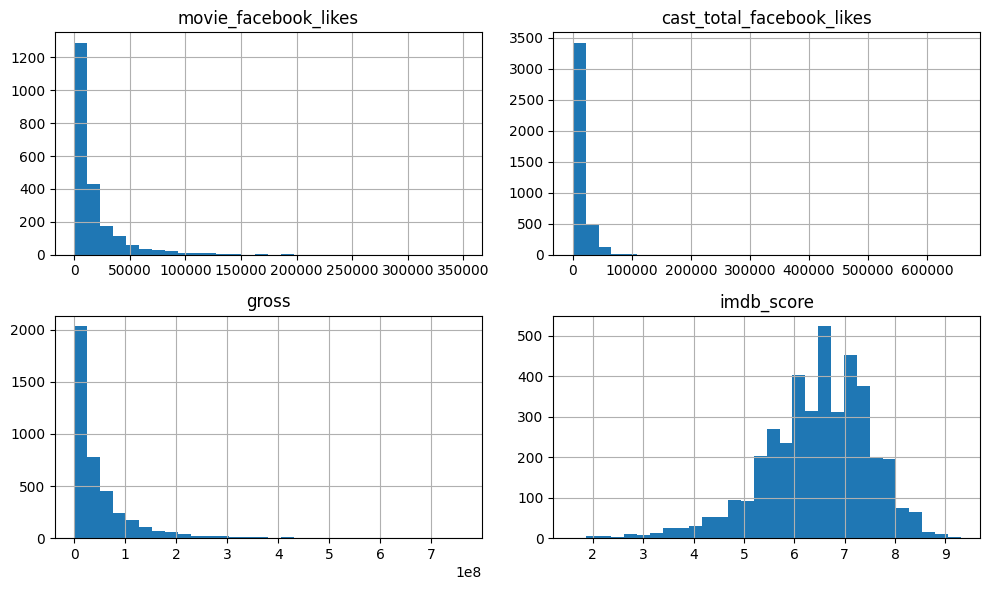

In [ ]:
import matplotlib.pyplot as plt

cols = ["movie_facebook_likes", "cast_total_facebook_likes", "gross", "imdb_score"]
df_limpo[cols].hist(bins=30, figsize=(10, 6))
plt.tight_layout()
plt.show()


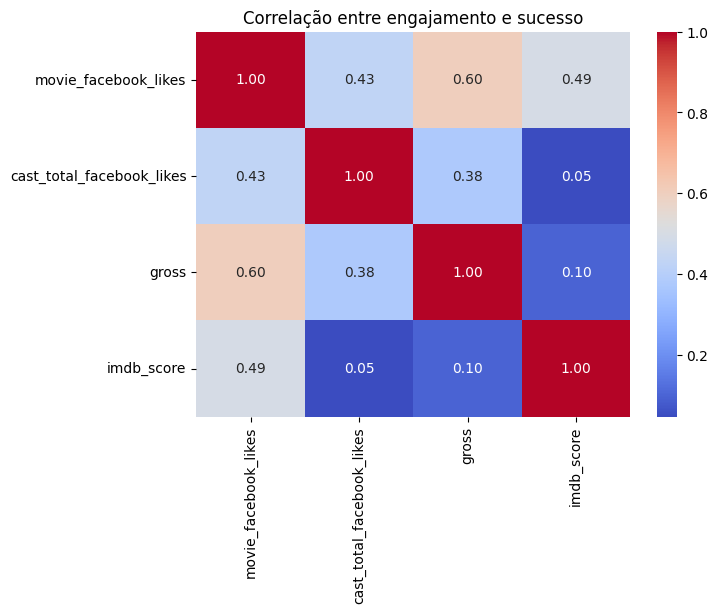

In [ ]:
import seaborn as sns

plt.figure(figsize=(7, 5))
sns.heatmap(df_limpo[cols].corr(method="spearman"), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlação entre engajamento e sucesso")
plt.show()

### Principais observações da exploração inicial

- A base tem 4059 filmes e 16 variáveis, depois da limpeza.
- Curtidas e bilheteria são muito assimétricas: poucos filmes concentram valores enormes (mediana bem menor que a média).
- movie_facebook_likes tem só 2198 valores preenchidos (cerca de metade da base).
- A correlação mais forte é entre curtidas do filme e bilheteria (0,60).
- A fama do elenco tem relação fraca com bilheteria (0,38) e quase nula com a nota do IMDb (0,05).
- Bilheteria e nota do IMDb quase não se relacionam (0,10).
- Correlação não prova causa: as relações precisam ser testadas na análise das hipóteses.

In [ ]:
df_limpo[["movie_title", "title_year", "country", "movie_facebook_likes", "gross", "imdb_score"]].head(10)

,movie_title,title_year,country,movie_facebook_likes,gross,imdb_score
0,Avatar,2009,USA,33000.0,760505847.0,7.9
1,Pirates of the Caribbean: At World's End,2007,USA,NaN,309404152.0,7.1
2,Spectre,2015,UK,85000.0,200074175.0,6.8
3,The Dark Knight Rises,2012,USA,164000.0,448130642.0,8.5
4,John Carter,2012,USA,24000.0,73058679.0,6.6
5,Spider-Man 3,2007,USA,NaN,336530303.0,6.2
6,Tangled,2010,USA,29000.0,200807262.0,7.8
7,Avengers: Age of Ultron,2015,USA,118000.0,458991599.0,7.5
8,Harry Potter and the Half-Blood Prince,2009,UK,10000.0,301956980.0,7.5
9,Batman v Superman: Dawn of Justice,2016,USA,197000.0,330249062.0,6.9


## 4. Base do YouTube (Movies YouTube Trailers & Sentiment)

In [ ]:
# Baixa a base do YouTube direto do Kaggle
path_yt = baixar_dataset("paultimothymooney/movies-youtube-trailers-sentiment")

arquivo_yt = [f for f in os.listdir(path_yt) if f.endswith(".csv")][0]
df_yt = pd.read_csv(os.path.join(path_yt, arquivo_yt))

print("YouTube carregado com sucesso:", df_yt.shape)
descrever_base(df_yt, "Movies YouTube Trailers & Sentiment (original)")

In [ ]:
def limpar_youtube(df):
    """Limpa a base do YouTube antes de juntar com o IMDb."""
    df = df.copy()
    antes = len(df)

    # Linhas totalmente repetidas contariam o mesmo filme duas vezes
    df = df.drop_duplicates()

    # Sem nome ou ano não dá para casar com o IMDb; o ano precisa ser número
    df["year"] = pd.to_numeric(df["year"], errors="coerce")
    df = df.dropna(subset=["name", "year"])
    df["year"] = df["year"].astype(int)

    # Padroniza o nome (espaços nas pontas)
    df["name"] = df["name"].astype(str).str.strip()

    print("Antes:", antes, "| Depois:", len(df), "| Removidas:", antes - len(df))
    return df.reset_index(drop=True)


df_yt = limpar_youtube(df_yt)
print("\nValores ausentes nas colunas mais usadas:")
print(df_yt[["name", "year", "favorability"]].isna().sum())

### Decisões de limpeza (YouTube)
- **Duplicados:** linhas totalmente repetidas foram removidas.
- **Nome e ano ausentes:** removidos, porque o casamento com o IMDb depende dos dois.
- **Tipos:** o ano virou número inteiro e o nome teve os espaços das pontas removidos.
- **Favorabilidade ausente:** não removemos nesta etapa. Os filmes continuam na base e só deixam de entrar nas análises que usam essa variável.

## 5. Integração IMDb + YouTube

A ligação entre as bases é feita pelo **título (em minúsculas) + ano**. Só o título não basta, porque existem filmes com o mesmo nome em anos diferentes.

In [ ]:
def criar_chave(titulos):
    """Título em minúsculas e sem espaços nas pontas, para casar as duas bases."""
    return titulos.astype(str).str.strip().str.lower()


def juntar_imdb_youtube(df_imdb, df_youtube):
    """Junta as bases por título + ano (só os filmes que existem nas duas)."""
    return df_imdb.merge(
        df_youtube,
        left_on=["chave", "title_year"],
        right_on=["chave", "year"],
        how="inner",
        suffixes=("_imdb", "_yt"),
    )


df_limpo["chave"] = criar_chave(df_limpo["movie_title"])
df_yt["chave"] = criar_chave(df_yt["name"])

df_final = juntar_imdb_youtube(df_limpo, df_yt)

print("Filmes no IMDb limpo:", len(df_limpo))
print("Filmes no YouTube:", len(df_yt))
print("Filmes que casaram:", len(df_final))

In [ ]:
casaram = df_final[["chave", "year"]].drop_duplicates()
nao = df_yt.merge(casaram, on=["chave", "year"], how="left", indicator=True)
nao = nao[nao["_merge"] == "left_only"]
print("Não casaram:", len(nao))

so_titulo = nao.merge(df_limpo[["chave", "title_year"]], on="chave", how="inner")
print("Desses, existem no IMDb com outro ano:", len(so_titulo))

nao[["name", "year"]].head(15)

In [ ]:
print("Linhas repetidas:", df_final.duplicated(subset=["chave", "year"]).sum())
df_final = df_final.drop_duplicates(subset=["chave", "year"]).copy()
print("Filmes na base final:", len(df_final))

colunas = ["movie_facebook_likes", "director_facebook_likes", "cast_total_facebook_likes",
           "gross_imdb", "budget_imdb", "imdb_score", "favorability"]
print(df_final[colunas].notna().sum())

In [ ]:
df_final.to_csv("filmes_final.csv", index=False)

print(df_final["title_year"].describe())
print(df_final["title_year"].value_counts().head(5))


In [ ]:
cols_final = ["movie_facebook_likes", "director_facebook_likes", "cast_total_facebook_likes",
              "gross_imdb", "imdb_score", "favorability", "votes", "runtime"]
df_final[cols_final].describe().T

In [ ]:
import matplotlib.pyplot as plt

cols_hist = ["movie_facebook_likes", "gross_imdb", "imdb_score", "favorability"]
df_final[cols_hist].hist(bins=30, figsize=(10, 6))
plt.tight_layout()
plt.show()

In [ ]:
import seaborn as sns

cols_corr = ["movie_facebook_likes", "cast_total_facebook_likes", "director_facebook_likes",
             "favorability", "gross_imdb", "imdb_score", "votes"]

plt.figure(figsize=(9, 6))
sns.heatmap(df_final[cols_corr].corr(method="spearman"), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlação (base final IMDb + YouTube)")
plt.show()

### Principais observações da base final (IMDb + YouTube)

- A base final tem 642 filmes únicos, de 1980 a 2016, concentrados entre 2006 e 2012.
- Esses filmes são mais populares que a média do IMDb 5000: a mediana das curtidas do filme é 17.000 (antes 5.000) e a da bilheteria é ~33,5 milhões (antes ~25 milhões).
- movie_facebook_likes tem 329 valores, director_facebook_likes 534 e budget 476.
- Curtidas e bilheteria continuam muito assimétricas; imdb_score e favorability têm formato de sino.
- A correlação entre curtidas do filme e bilheteria caiu de 0,60 (base do IMDb) para 0,36 (base final).
- A favorabilidade dos comentários tem correlação fraca com todas as variáveis (0,05 a 0,27), a maior com a nota do IMDb.
- O número de votos no IMDb é a variável mais ligada às demais (0,64 com curtidas do filme, 0,63 com bilheteria).
- Limitações: base concentrada em uma época, só filmes com trailer comentado no YouTube, e correlação não prova causa.

In [ ]:
df_final[["movie_title", "title_year", "movie_facebook_likes", "gross_imdb", "imdb_score", "favorability"]].head(10)

## 6. Terceira base: IMDB Dataset of 50K Movie Reviews

São 50.000 resenhas de filmes em texto (inglês), cada uma marcada como positiva ou negativa (25 mil de cada).

**Atenção:** essa base tem só duas colunas (`review` e `sentiment`), sem título nem ano do filme. Por isso não dá para juntar linha a linha, como foi feito com o YouTube. Para ligar as resenhas aos filmes da base final, procuramos o título de cada filme dentro do texto das resenhas.

In [ ]:
# Baixa a base de resenhas direto do Kaggle
path_rev = baixar_dataset("lakshmi25npathi/imdb-dataset-of-50k-movie-reviews")

arquivo_rev = [f for f in os.listdir(path_rev) if f.endswith(".csv")][0]
df_rev = pd.read_csv(os.path.join(path_rev, arquivo_rev))

print("Resenhas carregadas:", df_rev.shape)
print("Colunas:", df_rev.columns.tolist())
print(df_rev["sentiment"].value_counts())

In [ ]:
def limpar_reviews(df):
    """Limpa as resenhas: duplicadas, tags HTML e espaços extras."""
    df = df.copy()
    antes = len(df)

    df = df.dropna(subset=["review", "sentiment"])
    df = df.drop_duplicates()

    # As resenhas vêm com tags HTML (<br />)
    df["review"] = (df["review"]
                    .str.replace(r"<[^>]+>", " ", regex=True)
                    .str.replace(r"\s+", " ", regex=True)
                    .str.strip())

    df["positivo"] = (df["sentiment"] == "positive").astype(int)
    df["n_palavras"] = df["review"].str.split().str.len()

    print("Antes:", antes, "| Depois:", len(df), "| Removidas:", antes - len(df))
    return df.reset_index(drop=True)


df_rev = limpar_reviews(df_rev)
df_rev[["review", "sentiment", "positivo", "n_palavras"]].head()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df_rev, x="sentiment", hue="sentiment", order=["positive", "negative"],
              palette=["#2ca02c", "#d62728"], legend=False, ax=axes[0])
axes[0].set_title("Resenhas por sentimento", fontweight="bold")
axes[0].set_xlabel("Sentimento")
axes[0].set_ylabel("Quantidade")

# Corta o 1% mais longo só para o histograma ficar legível
limite = df_rev["n_palavras"].quantile(0.99)
sns.histplot(data=df_rev[df_rev["n_palavras"] <= limite], x="n_palavras", hue="sentiment",
             bins=50, ax=axes[1])
axes[1].set_title("Tamanho das resenhas (sem o 1% mais longo)", fontweight="bold")
axes[1].set_xlabel("Número de palavras")

plt.tight_layout()
plt.show()

print(df_rev.groupby("sentiment")["n_palavras"].describe())

### Ligação com os filmes: título dentro do texto

Como as resenhas não dizem de qual filme falam, usamos uma regra simples: uma resenha "cita" um filme quando o título aparece no texto (sem diferenciar maiúsculas, acentos e pontuação, e só como palavra inteira). Para cada filme da base final, calculamos:

- `rev_mencoes`: quantas resenhas citam o título;
- `rev_pct_positivo`: porcentagem dessas resenhas que é positiva.

Cuidados para reduzir erros:
- Títulos curtos e de uma palavra só (como "Up" ou "Fury") aparecem em muitos textos sem falar do filme, então só usamos títulos com 2 ou mais palavras, ou com 10 ou mais letras.
- Títulos que se repetem na base (refilmagens com o mesmo nome) são descartados, porque não dá para saber de qual ano é a resenha.
- Só analisamos filmes com pelo menos `MIN_MENCOES` resenhas, pois uma porcentagem calculada com 1 ou 2 resenhas não é confiável.

In [ ]:
def normalizar(txt):
    """Minúsculas, sem acento e sem pontuação (para comparar títulos e textos)."""
    txt = unicodedata.normalize("NFKD", str(txt)).encode("ascii", "ignore").decode()
    txt = re.sub(r"[^a-z0-9]+", " ", txt.lower())
    return txt.strip()


def contar_mencoes(df_filmes, df_resenhas):
    """Para cada filme, conta as resenhas que citam o título e a % delas que é positiva."""
    # Texto com espaço nas pontas: buscar " titulo " garante palavra inteira
    textos = df_resenhas["review"].map(lambda t: f" {normalizar(t)} ")
    positivo = df_resenhas["positivo"].to_numpy()

    titulos = df_filmes[["movie_title", "title_year"]].drop_duplicates().copy()
    titulos["titulo_norm"] = titulos["movie_title"].map(normalizar)
    total = len(titulos)

    # Descarta títulos repetidos (refilmagens) e títulos curtos demais
    titulos = titulos[~titulos["titulo_norm"].duplicated(keep=False)]
    titulos = titulos[(titulos["titulo_norm"].str.split().str.len() >= 2) |
                      (titulos["titulo_norm"].str.len() >= 10)]
    print("Títulos na base final:", total, "| Usados na busca:", len(titulos))

    linhas = []
    for _, t in titulos.iterrows():
        achou = textos.str.contains(f" {t['titulo_norm']} ", regex=False).to_numpy()
        n = int(achou.sum())
        if n > 0:
            linhas.append({
                "movie_title": t["movie_title"],
                "title_year": t["title_year"],
                "rev_mencoes": n,
                "rev_pct_positivo": positivo[achou].mean(),
            })
    return pd.DataFrame(linhas, columns=["movie_title", "title_year", "rev_mencoes", "rev_pct_positivo"])


df_mencoes = contar_mencoes(df_final, df_rev)
print("Filmes citados em pelo menos 1 resenha:", len(df_mencoes))
print(f"Filmes citados em pelo menos {MIN_MENCOES} resenhas:", (df_mencoes["rev_mencoes"] >= MIN_MENCOES).sum())
df_mencoes.sort_values("rev_mencoes", ascending=False).head(10)

In [ ]:
# Junta as informações das resenhas na base final (IMDb + YouTube)
df_final_rev = df_final.merge(df_mencoes, on=["movie_title", "title_year"], how="left")
df_final_rev["rev_mencoes"] = df_final_rev["rev_mencoes"].fillna(0).astype(int)

# A porcentagem só vale com um mínimo de resenhas
df_final_rev.loc[df_final_rev["rev_mencoes"] < MIN_MENCOES, "rev_pct_positivo"] = np.nan

df_final_rev.to_csv("filmes_final_reviews.csv", index=False)

print("Filmes na base final:", len(df_final_rev))
print("Filmes com resenhas suficientes:", df_final_rev["rev_pct_positivo"].notna().sum())
df_final_rev[["movie_title", "title_year", "rev_mencoes", "rev_pct_positivo", "imdb_score", "favorability"]].dropna(subset=["rev_pct_positivo"]).head(10)

In [ ]:
cols_rev = ["rev_mencoes", "rev_pct_positivo", "imdb_score", "favorability",
            "movie_facebook_likes", "gross_imdb"]
df_rev_ok = df_final_rev.dropna(subset=["rev_pct_positivo"])

if len(df_rev_ok) < 10:
    print(f"Só {len(df_rev_ok)} filmes com resenhas suficientes. Diminua MIN_MENCOES para ter mais.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    sns.heatmap(df_rev_ok[cols_rev].corr(method="spearman"), annot=True,
                cmap="coolwarm", fmt=".2f", ax=axes[0])
    axes[0].set_title("Correlação (filmes citados nas resenhas)", fontweight="bold")

    sns.regplot(data=df_rev_ok, x="rev_pct_positivo", y="imdb_score",
                scatter_kws={"alpha": 0.55, "color": "#9467bd"},
                line_kws={"color": "#111111", "linewidth": 2}, ax=axes[1])
    axes[1].set_title("% de resenhas positivas vs. Nota IMDb", fontweight="bold")
    axes[1].set_xlabel("% de resenhas positivas (base de 50K resenhas)")
    axes[1].set_ylabel("Nota no IMDb (0 - 10)")

    plt.tight_layout()
    plt.show()

In [ ]:
# Leitura automática dos resultados desta seção
n_ok = df_final_rev["rev_pct_positivo"].notna().sum()
print(f"Filmes da base final citados em pelo menos {MIN_MENCOES} resenhas: {n_ok} de {len(df_final_rev)}")

if n_ok >= 10:
    descrever_relacao(df_rev_ok, "rev_pct_positivo", "imdb_score", "% de resenhas positivas x nota do IMDb")
    descrever_relacao(df_rev_ok, "rev_mencoes", "gross_imdb", "Nº de resenhas que citam o filme x bilheteria")

**Como ler:** as resenhas vêm do próprio IMDb, então a % de resenhas positivas *deveria* acompanhar a nota do IMDb. Se acompanha, a ligação por título está funcionando e podemos confiar nessa base como medida de opinião. Se não acompanha, a ligação está fraca.

**Limitações desta base:**
- A base não informa o filme de cada resenha. Citar o título não garante que a resenha seja sobre aquele filme (ela pode comparar com outro, ou falar de uma sequência).
- Ela não aumenta o número de filmes (continuam os mesmos da base final): acrescenta informação de opinião em texto só para os filmes que foram citados.
- As resenhas são do IMDb e a maioria é de filmes até o início dos anos 2010, então filmes mais recentes têm pouca ou nenhuma citação.

## 7. Hipóteses e plano de análise

A pergunta principal é: *o engajamento nas redes sociais pode indicar o sucesso de um filme?* Para respondê-la, formulamos as hipóteses abaixo. Cada uma liga uma medida de engajamento a uma medida de sucesso e espera uma relação **positiva**.

| Código | Hipótese | Engajamento (x) | Sucesso (y) |
|---|---|---|---|
| H1 | Filmes com mais curtidas na página do Facebook têm maior bilheteria | `movie_facebook_likes` | `gross_imdb` |
| H2 | Filmes com elenco mais curtido têm maior bilheteria | `cast_total_facebook_likes` | `gross_imdb` |
| H3 | Filmes com diretor mais curtido têm maior bilheteria | `director_facebook_likes` | `gross_imdb` |
| H4 | Trailers com comentários mais positivos no YouTube têm maior nota no IMDb | `favorability` | `imdb_score` |
| H5 | Trailers com comentários mais positivos no YouTube têm maior bilheteria | `favorability` | `gross_imdb` |
| H6 | *(validação)* Filmes com mais resenhas positivas na base de 50K têm maior nota no IMDb | `rev_pct_positivo` | `imdb_score` |

**Plano de análise**
1. Visualizar as relações (seção 8): dispersão, sentimento do trailer e faixas de engajamento.
2. Testar cada hipótese com correlação de **Spearman** e p-valor (seção 9). Escolhemos Spearman porque curtidas e bilheteria são muito assimétricas, com poucos filmes concentrando valores enormes.
3. Considerar uma hipótese **apoiada pelos dados** quando a correlação é positiva e o p-valor é menor que 0,05. Também informamos a força da relação (desprezível, fraca, moderada ou forte), porque com muitos filmes até uma relação minúscula pode ser significativa.
4. Comparar a bilheteria entre faixas de engajamento (baixo, médio, alto) com o teste de Kruskal-Wallis.
5. Checar se o **orçamento** explica a relação: filmes caros têm mais curtidas e mais bilheteria, então calculamos a correlação parcial controlando o orçamento.

## 8. Visualizações

### Gráfico 1: Dispersão (Curtidas vs. Bilheteria)

**Como ler:** cada ponto é um filme. Os dois eixos estão em escala logarítmica (log10), porque poucos filmes têm valores enormes e comprimiriam todo o resto. A reta vermelha é a tendência ajustada nos valores em log.

In [ ]:
def grafico_dispersao(df):
    """Curtidas da página do filme x bilheteria, em log10."""
    d = df.dropna(subset=["movie_facebook_likes", "gross_imdb"]).copy()
    d = d[(d["movie_facebook_likes"] > 0) & (d["gross_imdb"] > 0)]
    d["log_curtidas"] = np.log10(d["movie_facebook_likes"])
    d["log_bilheteria"] = np.log10(d["gross_imdb"])

    plt.figure(figsize=(9, 5))
    sns.regplot(data=d, x="log_curtidas", y="log_bilheteria",
                scatter_kws={"alpha": 0.55, "color": "#1f77b4"},
                line_kws={"color": "#d62728", "linewidth": 2})
    plt.title("Curtidas da Página do Filme vs. Bilheteria Bruta (log10)", fontsize=12, fontweight="bold")
    plt.xlabel("Curtidas no Facebook (log10)", fontsize=11)
    plt.ylabel("Bilheteria no IMDb em USD (log10)", fontsize=11)
    plt.tight_layout()
    plt.show()


grafico_dispersao(df_final)
descrever_relacao(df_final, "movie_facebook_likes", "gross_imdb", "Curtidas do filme x bilheteria")

**Leitura:** a nuvem de pontos sobe da esquerda para a direita, então filmes com mais curtidas tendem a ter mais bilheteria. Mas os pontos ficam espalhados em volta da reta: há filmes com poucas curtidas e bilheteria alta, e o contrário. Na análise exploratória, essa correlação caiu de 0,60 (base IMDb) para 0,36 (base final). Ou seja, as curtidas dão uma pista da bilheteria, mas não a determinam.

### Gráfico 2: Sentimento no trailer vs. Nota e Bilheteria

**Como ler:** o eixo x é a taxa de favorabilidade dos comentários do trailer no YouTube (quanto maior, mais positivos os comentários). À esquerda, comparamos com a nota do IMDb; à direita, com a bilheteria (em log10).

In [ ]:
def grafico_sentimento(df):
    """Favorabilidade dos comentários do trailer x nota IMDb e x bilheteria (log10)."""
    d = df.dropna(subset=["favorability", "imdb_score", "gross_imdb"]).copy()
    d = d[d["gross_imdb"] > 0]
    d["log_bilheteria"] = np.log10(d["gross_imdb"])

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    sns.regplot(data=d, x="favorability", y="imdb_score", ax=axes[0],
                scatter_kws={"alpha": 0.45, "color": "#2ca02c"},
                line_kws={"color": "#111111", "linewidth": 2})
    axes[0].set_title("Sentimento nos Comentários vs. Nota IMDb", fontsize=12, fontweight="bold")
    axes[0].set_xlabel("Taxa de Favorabilidade (YouTube)")
    axes[0].set_ylabel("Nota no IMDb (0 - 10)")

    sns.regplot(data=d, x="favorability", y="log_bilheteria", ax=axes[1],
                scatter_kws={"alpha": 0.45, "color": "#ff7f0e"},
                line_kws={"color": "#111111", "linewidth": 2})
    axes[1].set_title("Sentimento nos Comentários vs. Bilheteria", fontsize=12, fontweight="bold")
    axes[1].set_xlabel("Taxa de Favorabilidade (YouTube)")
    axes[1].set_ylabel("Bilheteria em USD (log10)")

    plt.tight_layout()
    plt.show()


grafico_sentimento(df_final)
descrever_relacao(df_final, "favorability", "imdb_score", "Favorabilidade x nota IMDb")
descrever_relacao(df_final, "favorability", "gross_imdb", "Favorabilidade x bilheteria")

**Leitura:** os pontos formam uma nuvem larga, sem uma direção clara. Na análise exploratória, a favorabilidade teve correlação fraca com todas as variáveis (entre 0,05 e 0,27), e a maior foi com a nota do IMDb. Então o sentimento do trailer diz um pouco sobre a *qualidade percebida* do filme, e quase nada sobre quanto ele arrecada.

### Gráfico 3: Boxplot por faixas de engajamento

**Como ler:** dividimos os filmes em três grupos de mesmo tamanho pelas curtidas da página (baixo, médio e alto engajamento). Cada caixa mostra a distribuição da bilheteria do grupo (escala log); a linha dentro da caixa é a mediana e o ponto vermelho é a média.

In [ ]:
FAIXAS = ["Baixo Engajamento", "Médio Engajamento", "Alto Engajamento"]


def grafico_faixas(df):
    """Boxplot da bilheteria por faixa de curtidas (tercis). Devolve a base com a faixa."""
    d = df.dropna(subset=["movie_facebook_likes", "gross_imdb"]).copy()
    d["faixa_engajamento"] = pd.qcut(d["movie_facebook_likes"], q=3, labels=FAIXAS)

    plt.figure(figsize=(9, 5))
    sns.boxplot(data=d, x="faixa_engajamento", y="gross_imdb", hue="faixa_engajamento",
                palette="Blues", legend=False, showmeans=True,
                meanprops={"marker": "o", "markerfacecolor": "red", "markeredgecolor": "black"})
    plt.yscale("log")
    plt.title("Distribuição da Bilheteria por Faixa de Engajamento", fontsize=12, fontweight="bold")
    plt.xlabel("Volume de Curtidas na Rede Social")
    plt.ylabel("Bilheteria em USD (Escala Log)")
    plt.tight_layout()
    plt.show()
    return d


df_bins = grafico_faixas(df_final)

medianas = df_bins.groupby("faixa_engajamento", observed=True)["gross_imdb"].median()
print("Mediana da bilheteria por faixa (USD):")
print(medianas.round(0))
cresce = medianas.is_monotonic_increasing
print("\nA mediana da bilheteria", "aumenta" if cresce else "não aumenta de forma contínua",
      "da faixa de baixo para a de alto engajamento.")

**Leitura:** compare as três medianas impressas acima. Se elas crescem de "Baixo" para "Alto", filmes mais engajados tendem a faturar mais. As caixas também se sobrepõem bastante: existem filmes de baixo engajamento com bilheteria maior que a de filmes de alto engajamento. O teste de Kruskal-Wallis na seção 9 diz se a diferença entre as faixas é grande demais para ser acaso.

## 9. Teste das hipóteses

Aplicamos o plano da seção 7: correlação de Spearman com p-valor para cada hipótese. Uma hipótese é **apoiada pelos dados** quando a correlação é positiva e `p < 0,05`.

In [ ]:
HIPOTESES = [
    # (código, descrição, x (engajamento), y (sucesso), tipo)
    ("H1", "Curtidas do filme -> bilheteria", "movie_facebook_likes", "gross_imdb", "rede social"),
    ("H2", "Curtidas do elenco -> bilheteria", "cast_total_facebook_likes", "gross_imdb", "rede social"),
    ("H3", "Curtidas do diretor -> bilheteria", "director_facebook_likes", "gross_imdb", "rede social"),
    ("H4", "Favorabilidade do trailer -> nota IMDb", "favorability", "imdb_score", "rede social"),
    ("H5", "Favorabilidade do trailer -> bilheteria", "favorability", "gross_imdb", "rede social"),
    ("H6", "% de resenhas positivas -> nota IMDb (validação)", "rev_pct_positivo", "imdb_score", "validação"),
]


def veredito(rho, p):
    """Diz se a hipótese (relação positiva) é apoiada pelos dados."""
    if np.isnan(rho):
        return "Sem dados suficientes"
    if p >= ALFA:
        return "Não apoiada (relação não significativa)"
    if rho <= 0:
        return "Não apoiada (relação negativa)"
    if abs(rho) < 0.10:
        return "Apoiada, mas com efeito desprezível"
    return f"Apoiada ({classificar_forca(rho)})"


def testar_hipoteses(df, hipoteses):
    """Roda Spearman para cada hipótese e devolve uma tabela com os resultados."""
    linhas = []
    for cod, texto, x, y, tipo in hipoteses:
        if x not in df.columns or y not in df.columns:
            continue
        r = correlacao_spearman(df, x, y)
        linhas.append({
            "hipotese": cod, "descricao": texto, "tipo": tipo, "x": x, "y": y,
            "n": r["n"], "rho": r["rho"], "p_valor": r["p"],
            "forca": "-" if np.isnan(r["rho"]) else classificar_forca(r["rho"]),
            "veredito": veredito(r["rho"], r["p"]),
        })
    return pd.DataFrame(linhas)


# df_final_rev tem todas as colunas de df_final mais as das resenhas
df_res = testar_hipoteses(df_final_rev, HIPOTESES)
df_res.to_csv("resultados_hipoteses.csv", index=False)

tabela = df_res[["hipotese", "descricao", "n", "rho", "p_valor", "forca", "veredito"]].copy()
tabela["rho"] = tabela["rho"].round(2)
tabela["p_valor"] = tabela["p_valor"].map(lambda p: f"{p:.3g}")
tabela

In [ ]:
def grafico_resultados(df_res):
    """Barras com a correlação de cada hipótese; azul = significativa (p < 0,05)."""
    d = df_res.dropna(subset=["rho"]).copy()
    d["significância"] = np.where(d["p_valor"] < ALFA, "p < 0,05", "p ≥ 0,05")

    plt.figure(figsize=(9, 0.7 * len(d) + 2))
    sns.barplot(data=d, y="hipotese", x="rho", hue="significância", dodge=False,
                palette={"p < 0,05": "#1f77b4", "p ≥ 0,05": "#bbbbbb"})
    plt.axvline(0, color="black", linewidth=1)
    for i, v in enumerate(d["rho"]):
        plt.text(v + (0.01 if v >= 0 else -0.01), i, f"{v:.2f}",
                 va="center", ha="left" if v >= 0 else "right")
    plt.title("Correlação de Spearman por hipótese", fontsize=12, fontweight="bold")
    plt.xlabel("Correlação (rho)")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()


grafico_resultados(df_res)

In [ ]:
def teste_faixas(df, x="movie_facebook_likes", y="gross_imdb"):
    """Compara a bilheteria entre 3 faixas de engajamento (Kruskal-Wallis)."""
    d = df.dropna(subset=[x, y]).copy()
    d["faixa"] = pd.qcut(d[x], q=3, labels=FAIXAS)
    grupos = [g[y].to_numpy() for _, g in d.groupby("faixa", observed=True)]
    h, p = stats.kruskal(*grupos)
    return d.groupby("faixa", observed=True)[y].median(), h, p


medianas, h, p = teste_faixas(df_final)
print("Kruskal-Wallis: bilheteria x faixa de curtidas do filme")
print(medianas.round(0).to_string())
print(f"\nH = {h:.2f}, p = {p:.3g} ->",
      "há diferença significativa entre as faixas." if p < ALFA else "não há diferença significativa entre as faixas.")

In [ ]:
def correlacao_parcial_spearman(df, x, y, z):
    """Correlação (em postos) entre x e y depois de tirar o efeito de z.
    Devolve também a correlação simples nas mesmas linhas, para comparar."""
    d = df[[x, y, z]].dropna()
    n = len(d)
    if n < 10:
        return {"n": n, "simples": np.nan, "parcial": np.nan, "p": np.nan}
    r = d.rank()

    def residuo(a, b):
        coef = np.polyfit(b, a, 1)
        return a - np.polyval(coef, b)

    parcial = np.corrcoef(residuo(r[x], r[z]), residuo(r[y], r[z]))[0, 1]
    t = parcial * np.sqrt((n - 3) / (1 - parcial ** 2))
    p = 2 * stats.t.sf(abs(t), n - 3)   # p-valor aproximado (t com n-3 graus de liberdade)
    return {"n": n, "simples": stats.spearmanr(d[x], d[y])[0], "parcial": parcial, "p": p}


print("O orçamento explica a relação? (correlação com e sem controlar o orçamento)\n")
for x, nome in [("movie_facebook_likes", "H1 curtidas do filme"), ("cast_total_facebook_likes", "H2 curtidas do elenco")]:
    r = correlacao_parcial_spearman(df_final, x, "gross_imdb", "budget_imdb")
    if np.isnan(r["parcial"]):
        print(f"{nome}: poucos filmes com orçamento (n = {r['n']}).")
        continue
    print(f"{nome} x bilheteria (n = {r['n']}): rho = {r['simples']:.2f} -> "
          f"rho controlando orçamento = {r['parcial']:.2f} (p = {r['p']:.3g})")

**Como ler:** o orçamento é uma variável de confusão. Filmes caros costumam ter mais divulgação (mais curtidas) e mais bilheteria ao mesmo tempo, então parte da relação pode ser efeito do orçamento. Se a correlação cai bastante depois de controlá-lo, o engajamento explica pouco além do que o dinheiro investido já explica. Só temos orçamento dos filmes dos EUA (ver decisões de limpeza), por isso o *n* é menor.

## 10. Conclusões e limitações

### Resposta às hipóteses (gerada a partir dos resultados da seção 9)

In [ ]:
def escrever_conclusao(df_res):
    """Escreve o veredito de cada hipótese e a resposta à pergunta principal."""
    for _, l in df_res.iterrows():
        rho = "sem dados" if np.isnan(l["rho"]) else f"rho = {l['rho']:.2f}, n = {l['n']}"
        print(f"{l['hipotese']} ({l['descricao']}): {l['veredito']} [{rho}]")

    rede = df_res[df_res["tipo"] == "rede social"].dropna(subset=["rho"])
    apoiadas = rede[rede["veredito"].str.startswith("Apoiada")]
    print(f"\nHipóteses sobre redes sociais apoiadas pelos dados: {len(apoiadas)} de {len(rede)}.")

    if apoiadas.empty:
        print("Resposta: os dados não sustentam que o engajamento nas redes sociais indique o sucesso do filme.")
        return

    melhor = apoiadas.loc[apoiadas["rho"].idxmax()]
    print(f"A relação mais forte foi {melhor['hipotese']} ({melhor['descricao']}): "
          f"rho = {melhor['rho']:.2f}, {melhor['forca']}.")
    if melhor["rho"] < 0.30:
        leitura = "traz alguma informação sobre o sucesso, mas pouca: sozinho, não é um bom indicador."
    elif melhor["rho"] < 0.50:
        leitura = "é um indicador parcial do sucesso: ajuda a prever, mas deixa muita coisa de fora."
    else:
        leitura = "é um bom indicador do sucesso."
    print("Resposta: o engajamento nas redes sociais", leitura)
    print("Lembrete: correlação não prova causa.")


escrever_conclusao(df_res)

### Principais insights (valores da análise exploratória)
- **Curtidas do filme são o melhor sinal de bilheteria** entre as medidas de rede social: correlação de 0,60 na base do IMDb e 0,36 na base final.
- **O sentimento do trailer quase não se liga à bilheteria.** Ele se liga um pouco mais à nota do IMDb (0,27), ou seja, mede mais a qualidade percebida do que o sucesso comercial.
- **A fama do elenco ajuda na bilheteria, mas não na nota:** 0,38 com a bilheteria e 0,05 com a nota do IMDb.
- **O número de votos no IMDb é a variável mais ligada às demais** (0,64 com as curtidas do filme e 0,63 com a bilheteria). O engajamento dentro da própria plataforma de cinema acompanha o sucesso melhor que o sentimento dos comentários.
- **Bilheteria e nota quase não se relacionam** (0,10): um filme pode ser sucesso de público sem ser bem avaliado, e o contrário.

### Limitações
- **Viés de seleção:** a base final só inclui filmes com trailer comentado no YouTube e é mais popular que a média (mediana de curtidas de 17.000 contra 5.000 na base original).
- **Período:** os filmes se concentram entre 2006 e 2012. O comportamento nas redes sociais mudou muito desde então, e as curtidas do Facebook foram medidas em um momento só, não ao longo do tempo.
- **Dados ausentes:** a página do filme no Facebook só existe para cerca de metade dos filmes, e o orçamento só foi mantido para filmes dos EUA.
- **Resenhas:** a ligação com os filmes é feita pelo título dentro do texto, o que gera erros (ver seção 6).
- **Causalidade:** correlação não prova causa. Filmes grandes têm mais divulgação, mais curtidas e mais bilheteria ao mesmo tempo (o teste do orçamento na seção 9 trata parte disso).

